# Machine Maintenance Insight — Round 2: EDA and Feature Engineering
**Use case:** MechaCare Industrial Systems  
**Scope:** Round 2 implementation using only the five supplied CSV datasets. Round 1 quiz is excluded.  
**Data note:** The included datasets are synthetic and created for this educational assessment.

## Business question
What operating patterns indicate machines that require maintenance attention?

## Assessment questions
1. Which machines show abnormal sensor ranges?
2. How do readings change before maintenance?
3. Which alarms occur most often?
4. Does load relate to downtime?
5. Which machine types require more service?
6. What patterns appear in repeated failures?

This notebook loads the CSVs from `datasets/`. It does **not** generate or fabricate datasets. It creates analysis outputs in `outputs/`.

In [1]:
# If needed, install these once in your environment:
# %pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

ROOT = Path.cwd()
DATA_DIR = ROOT / "datasets"
OUTPUT_DIR = ROOT / "outputs"
CHART_DIR = OUTPUT_DIR / "charts"
OUTPUT_DIR.mkdir(exist_ok=True)
CHART_DIR.mkdir(exist_ok=True)

required_files = ["sensor.csv", "machines.csv", "usage.csv", "alarms.csv", "maintenance.csv"]
missing_files = [name for name in required_files if not (DATA_DIR / name).exists()]
if missing_files:
    raise FileNotFoundError(
        f"Missing required CSV files in {DATA_DIR}: {missing_files}. "
        "Keep the datasets folder beside this notebook and run from the project root."
    )

sensor = pd.read_csv(DATA_DIR / "sensor.csv", parse_dates=["timestamp"])
machines = pd.read_csv(DATA_DIR / "machines.csv", parse_dates=["installation_date"])
usage = pd.read_csv(DATA_DIR / "usage.csv", parse_dates=["date"])
alarms = pd.read_csv(DATA_DIR / "alarms.csv", parse_dates=["timestamp"])
maintenance = pd.read_csv(DATA_DIR / "maintenance.csv", parse_dates=["service_date"])

print("Loaded exactly five source datasets:")
for name, frame in {"sensor": sensor, "machines": machines, "usage": usage,
                     "alarms": alarms, "maintenance": maintenance}.items():
    print(f"{name:12s}: {frame.shape[0]:,} rows × {frame.shape[1]} columns")

Loaded exactly five source datasets:
sensor      : 23,000 rows × 5 columns
machines    : 16 rows × 4 columns
usage       : 960 rows × 5 columns
alarms      : 371 rows × 3 columns
maintenance : 20 rows × 4 columns


## 1. Understand the datasets and audit data quality
Check dimensions, data types, missing values, duplicate rows, duplicate sensor keys and numerical ranges before cleaning.

In [4]:
source_frames = {
    "sensor": sensor, "machines": machines, "usage": usage,
    "alarms": alarms, "maintenance": maintenance
}

audit_rows = []
for name, df in source_frames.items():
    audit_rows.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "missing_cells": int(df.isna().sum().sum()),
        "duplicate_full_rows": int(df.duplicated().sum()
    )})
quality_audit = pd.DataFrame(audit_rows)
display(quality_audit)
print("\nSensor duplicate (timestamp, machine) keys:",
      int(sensor.duplicated(["timestamp", "machine"]).sum()))
print("\nSensor dtypes:")
display(sensor.dtypes.rename("dtype").to_frame())
print("\nNumeric summary:")
display(sensor[["vibration", "temperature", "current"]].describe().T)
quality_audit.to_csv(OUTPUT_DIR / "data_quality_audit.csv", index=False)

,dataset,rows,columns,missing_cells,duplicate_full_rows
0,sensor,23000,5,0,70
1,machines,16,4,0,0
2,usage,960,5,0,0
3,alarms,371,3,0,0
4,maintenance,20,4,0,0



Sensor duplicate (timestamp, machine) keys: 70

Sensor dtypes:


,dtype
timestamp,datetime64[us]
machine,str
vibration,float64
temperature,float64
current,float64



Numeric summary:


,count,mean,std,min,25%,50%,75%,max
vibration,23000.0,1.233598,0.651982,0.383,1.0150,1.178,1.386,25.00
temperature,23000.0,66.941223,4.898213,-20.000,63.9400,66.700,69.670,160.00
current,23000.0,13.290667,1.767480,6.000,12.1075,13.270,14.480,20.61


## 2. Clean the data
Cleaning decisions:
- Remove duplicate sensor records using `(timestamp, machine)` as the natural key.
- Flag implausible sensor readings before replacing them with missing values.
- Interpolate only short within-machine gaps, then use the machine median for remaining missing sensor values.
- Normalize inconsistent alarm labels into a controlled vocabulary.
- Do not fabricate missing sensor timestamps. Record daily sensor completeness as an analysis feature.
- Keep raw source files unchanged; write cleaned outputs separately.

In [5]:
sensor_clean = sensor.drop_duplicates(["timestamp", "machine"], keep="first").copy()
outlier_counts = {}
for col, lower, upper in [
    ("vibration", 0, 8),
    ("temperature", 0, 120),
    ("current", 0, 40)
]:
    flag_col = f"{col}_outlier"
    sensor_clean[flag_col] = (sensor_clean[col] < lower) | (sensor_clean[col] > upper)
    outlier_counts[col] = int(sensor_clean[flag_col].sum())
    sensor_clean.loc[sensor_clean[flag_col], col] = np.nan

sensor_clean = sensor_clean.sort_values(["machine", "timestamp"]).reset_index(drop=True)
for col in ["vibration", "temperature", "current"]:
    sensor_clean[col] = sensor_clean.groupby("machine")[col].transform(
        lambda s: s.interpolate(limit=3).fillna(s.median())
    )
sensor_clean["date"] = sensor_clean["timestamp"].dt.floor("D")

def normalize_alarm(value):
    text = " ".join(str(value).strip().lower().replace("_", " ").replace("-", " ").split())
    if "vibration" in text:
        return "High Vibration"
    if "temp" in text:
        return "High Temperature"
    if "current" in text:
        return "Overcurrent"
    if "pressure" in text:
        return "Low Pressure"
    if "sensor fault" in text:
        return "Sensor Fault"
    return "Other"

alarms_clean = alarms.copy()
alarms_clean["alarm_type_raw"] = alarms_clean["alarm_type"]
alarms_clean["alarm_type"] = alarms_clean["alarm_type"].map(normalize_alarm)
alarms_clean["date"] = alarms_clean["timestamp"].dt.floor("D")

machines_clean = machines.copy()
usage_clean = usage.copy()
maintenance_clean = maintenance.copy()
usage_clean["date"] = pd.to_datetime(usage_clean["date"])
maintenance_clean["date"] = maintenance_clean["service_date"].dt.floor("D")

print("Duplicate sensor keys removed:", len(sensor) - len(sensor_clean))
print("Implausible readings flagged:", outlier_counts)
print("Normalized alarm categories:", sorted(alarms_clean["alarm_type"].unique()))

sensor_clean.to_csv(OUTPUT_DIR / "sensor_cleaned.csv", index=False)
alarms_clean.to_csv(OUTPUT_DIR / "alarms_cleaned.csv", index=False)
machines_clean.to_csv(OUTPUT_DIR / "machines_cleaned.csv", index=False)
usage_clean.to_csv(OUTPUT_DIR / "usage_cleaned.csv", index=False)
maintenance_clean.to_csv(OUTPUT_DIR / "maintenance_cleaned.csv", index=False)

Duplicate sensor keys removed: 70
Implausible readings flagged: {'vibration': 24, 'temperature': 12, 'current': 0}
Normalized alarm categories: ['High Temperature', 'High Vibration', 'Low Pressure', 'Overcurrent', 'Sensor Fault']


## 3. Exploratory data analysis (EDA)
Use distributions to understand sensor behavior, bar charts to compare alarm counts, and trends to identify potentially abnormal machines. The thresholds below are illustrative and must not be treated as manufacturer safety limits.

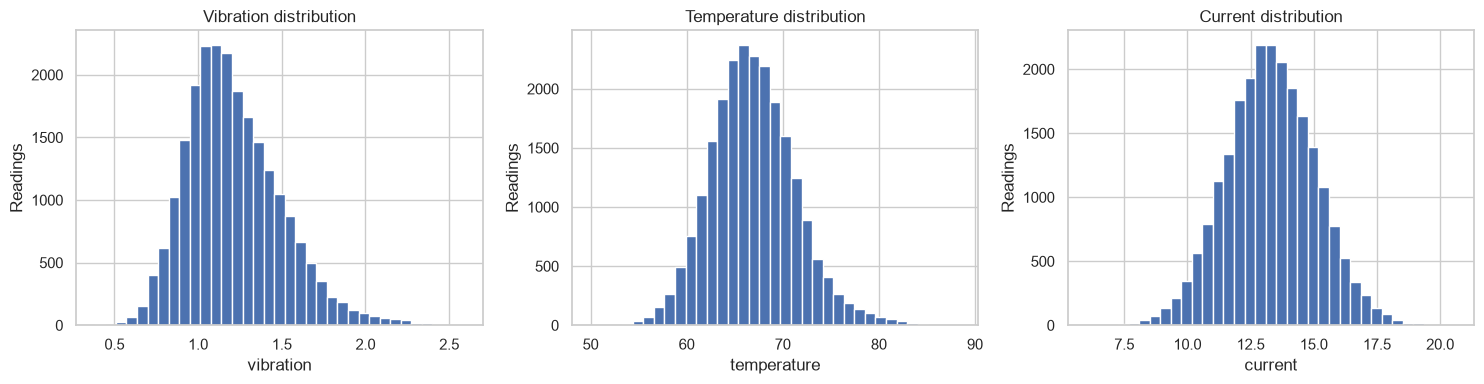

,alarm_type,count
0,High Temperature,86
1,Overcurrent,76
2,High Vibration,76
3,Sensor Fault,69
4,Low Pressure,64


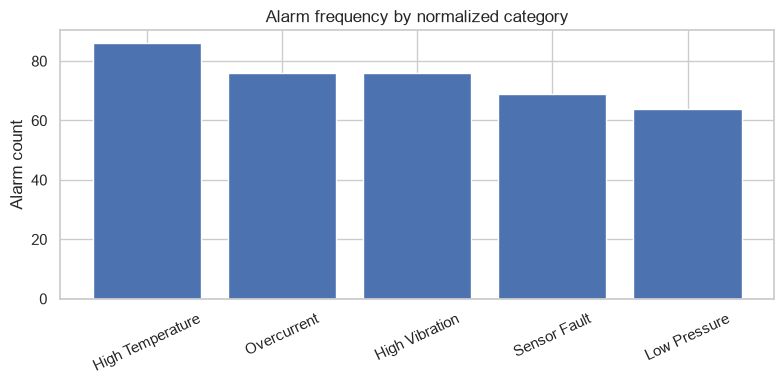

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["vibration", "temperature", "current"]):
    ax.hist(sensor_clean[col].dropna(), bins=35, edgecolor="white")
    ax.set_title(f"{col.title()} distribution")
    ax.set_xlabel(col)
    ax.set_ylabel("Readings")
plt.tight_layout()
plt.savefig(CHART_DIR / "sensor_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

alarm_frequency = alarms_clean["alarm_type"].value_counts().rename_axis("alarm_type").reset_index(name="count")
display(alarm_frequency)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(alarm_frequency["alarm_type"], alarm_frequency["count"])
ax.set_title("Alarm frequency by normalized category")
ax.set_ylabel("Alarm count")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.savefig(CHART_DIR / "alarm_frequency.png", dpi=160, bbox_inches="tight")
plt.show()
alarm_frequency.to_csv(OUTPUT_DIR / "alarm_frequency.csv", index=False)

## 4. Combine the data at machine-day level and engineer features
Daily aggregation aligns hourly sensor telemetry with daily usage and alarm counts. Rolling averages help expose persistent trends rather than isolated spikes.

In [7]:
sensor_daily = sensor_clean.groupby(["machine", "date"]).agg(
    mean_vibration=("vibration", "mean"),
    max_vibration=("vibration", "max"),
    mean_temperature=("temperature", "mean"),
    max_temperature=("temperature", "max"),
    mean_current=("current", "mean"),
    max_current=("current", "max"),
    sensor_readings=("timestamp", "count"),
    vibration_std=("vibration", "std")
).reset_index()
sensor_daily["vibration_std"] = sensor_daily["vibration_std"].fillna(0)

daily = sensor_daily.merge(usage_clean, on=["machine", "date"], how="left")
daily = daily.merge(machines_clean, on="machine", how="left")
alarm_daily = alarms_clean.groupby(["machine", "date"]).size().rename("alarm_count").reset_index()
daily = daily.merge(alarm_daily, on=["machine", "date"], how="left")
daily["alarm_count"] = daily["alarm_count"].fillna(0).astype(int)
daily["sensor_completeness"] = (daily["sensor_readings"] / 24).clip(upper=1)
daily = daily.sort_values(["machine", "date"]).reset_index(drop=True)

daily["vibration_rolling_7d"] = daily.groupby("machine")["mean_vibration"].transform(
    lambda s: s.rolling(7, min_periods=1).mean()
)
daily["temperature_rolling_7d"] = daily.groupby("machine")["mean_temperature"].transform(
    lambda s: s.rolling(7, min_periods=1).mean()
)
daily["high_vibration_flag"] = (daily["mean_vibration"] > 1.8).astype(int)
daily["high_temperature_flag"] = (daily["max_temperature"] > 90).astype(int)
daily["high_current_flag"] = (daily["max_current"] > 20).astype(int)
daily["warning_score"] = (
    daily[["high_vibration_flag", "high_temperature_flag", "high_current_flag"]].sum(axis=1)
    + (daily["alarm_count"] >= 2).astype(int)
)
daily.to_csv(OUTPUT_DIR / "machine_daily_features.csv", index=False)
display(daily.head())
print("Machine-day feature dataset:", daily.shape)

,machine,date,mean_vibration,max_vibration,mean_temperature,max_temperature,mean_current,max_current,sensor_readings,vibration_std,runtime,load,cycles,type,age,installation_date,alarm_count,sensor_completeness,vibration_rolling_7d,temperature_rolling_7d,high_vibration_flag,high_temperature_flag,high_current_flag,warning_score
0,M001,2026-01-01,1.077957,1.473,65.390870,71.93,12.591304,14.92,23,0.150691,17.55,0.833,622,CNC Mill,2,2023-06-23,0,0.958333,1.077957,65.390870,0,0,0,0
1,M001,2026-01-02,1.088333,1.484,65.553750,76.30,12.945417,15.54,24,0.212869,21.57,0.988,755,CNC Mill,2,2023-06-23,0,1.000000,1.083145,65.472310,0,0,0,0
2,M001,2026-01-03,1.049625,1.524,64.968750,71.82,12.850000,15.18,24,0.195837,14.96,0.553,600,CNC Mill,2,2023-06-23,1,1.000000,1.071972,65.304457,0,0,0,0
3,M001,2026-01-04,1.122542,1.397,66.229583,74.55,13.029583,17.10,24,0.191949,5.13,0.267,155,CNC Mill,2,2023-06-23,0,1.000000,1.084614,65.535738,0,0,0,0
4,M001,2026-01-05,1.065250,1.310,66.077917,72.71,12.689167,16.80,24,0.146135,17.17,0.832,637,CNC Mill,2,2023-06-23,1,1.000000,1.080741,65.644174,0,0,0,0


Machine-day feature dataset: (960, 24)


## 5. Answer the use-case analytical questions

,machine,type,age,avg_vibration,max_vibration,avg_temperature,max_temperature,total_alarms,avg_warning_score,warning_days
11,M012,Compressor,3,1.517711,2.498,69.690193,85.70,31,0.183333,1
5,M006,Hydraulic Press,7,1.511531,2.509,69.798257,86.69,26,0.183333,0
14,M015,Conveyor,7,1.515105,2.589,69.626748,88.42,29,0.166667,0
8,M009,CNC Mill,7,1.505603,2.375,69.649617,88.24,25,0.166667,2
2,M003,Conveyor,6,1.508204,2.475,69.984563,87.53,26,0.150000,2
10,M011,Conveyor,7,1.082537,1.670,65.584359,78.36,26,0.083333,0
6,M007,Conveyor,9,1.078196,1.711,65.647135,76.89,25,0.066667,0
7,M008,Compressor,9,1.078066,1.868,65.673438,78.80,24,0.066667,0
0,M001,CNC Mill,2,1.075444,1.673,65.579543,77.01,20,0.066667,0
4,M005,CNC Mill,3,1.091281,1.726,65.793752,80.68,19,0.066667,0


,machine,service_date,action,downtime_hours,days_observed,mean_vibration_before_service,mean_temperature_before_service,mean_alarms_per_day_before_service
0,M002,2026-01-27 22:00:00,Lubrication,1.74,7,1.075378,65.786074,0.000000
1,M003,2026-02-19 21:00:00,Calibration,2.84,7,1.439429,69.123899,0.428571
2,M003,2026-01-11 10:00:00,Bearing replacement,1.98,7,1.419447,68.860357,0.285714
3,M003,2026-01-23 15:00:00,Lubrication,3.86,7,1.436356,69.049702,0.142857
4,M004,2026-01-27 06:00:00,Lubrication,5.31,7,1.095221,65.915884,0.857143
5,M005,2026-02-24 13:00:00,Belt replacement,5.69,7,1.076494,65.331250,0.428571
6,M005,2026-03-01 21:00:00,Belt replacement,0.73,7,1.066682,65.478791,0.285714
7,M006,2026-02-08 14:00:00,Cooling-system service,8.21,7,1.456317,68.844754,0.428571
8,M006,2026-02-06 20:00:00,Lubrication,2.68,7,1.460733,68.729511,0.571429
9,M008,2026-02-28 19:00:00,Bearing replacement,0.63,7,1.056208,65.577342,0.571429


,alarm_type,count
0,High Temperature,86
1,Overcurrent,76
2,High Vibration,76
3,Sensor Fault,69
4,Low Pressure,64


Matched service events: 20
Pearson correlation between load and downtime: 0.108


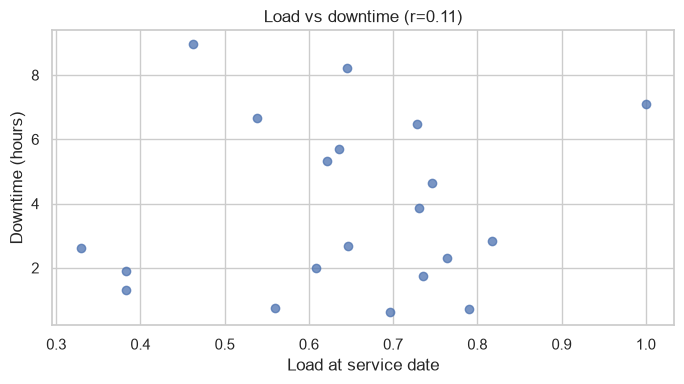

,type,machine_count,total_service_events,mean_services_per_machine,total_downtime_hours
0,CNC Mill,4,5.0,1.25,20.34
1,Compressor,4,6.0,1.50,16.38
2,Conveyor,4,6.0,1.50,27.04
3,Hydraulic Press,4,3.0,0.75,12.63


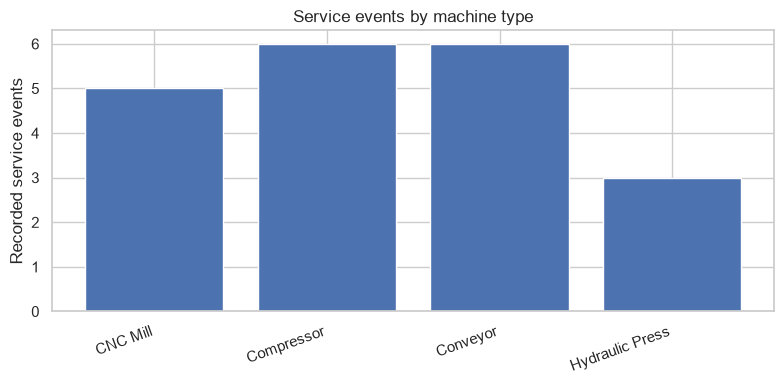

,machine,type,age,service_events,total_downtime,mean_downtime,avg_warning_score,total_alarms,warning_days
11,M012,Compressor,3,4.0,10.44,2.610000,0.183333,31,1
14,M015,Conveyor,7,3.0,18.36,6.120000,0.166667,29,0
2,M003,Conveyor,6,3.0,8.68,2.893333,0.150000,26,2
5,M006,Hydraulic Press,7,2.0,10.89,5.445000,0.183333,26,0
8,M009,CNC Mill,7,2.0,11.31,5.655000,0.166667,25,2
4,M005,CNC Mill,3,2.0,6.42,3.210000,0.066667,19,0
7,M008,Compressor,9,1.0,0.63,0.630000,0.066667,24,0
3,M004,Compressor,2,1.0,5.31,5.310000,0.033333,20,0
12,M013,CNC Mill,10,1.0,2.61,2.610000,0.033333,17,0
1,M002,Hydraulic Press,8,1.0,1.74,1.740000,0.016667,16,0


In [8]:
# Q1: Which machines show abnormal sensor ranges?
machine_risk = daily.groupby("machine").agg(
    type=("type", "first"),
    age=("age", "first"),
    avg_vibration=("mean_vibration", "mean"),
    max_vibration=("max_vibration", "max"),
    avg_temperature=("mean_temperature", "mean"),
    max_temperature=("max_temperature", "max"),
    total_alarms=("alarm_count", "sum"),
    avg_warning_score=("warning_score", "mean"),
    warning_days=("warning_score", lambda s: int((s >= 2).sum()))
).reset_index().sort_values(["avg_warning_score", "total_alarms"], ascending=False)
display(machine_risk.head(10))
machine_risk.to_csv(OUTPUT_DIR / "machine_risk_summary.csv", index=False)

# Q2: Sensor behavior in the seven days before each recorded service.
before_service_rows = []
for _, event in maintenance_clean.iterrows():
    service_day = event["service_date"].floor("D")
    window = daily[
        (daily["machine"] == event["machine"])
        & (daily["date"] >= service_day - pd.Timedelta(days=7))
        & (daily["date"] < service_day)
    ]
    if not window.empty:
        before_service_rows.append({
            "machine": event["machine"],
            "service_date": event["service_date"],
            "action": event["action"],
            "downtime_hours": event["downtime_hours"],
            "days_observed": len(window),
            "mean_vibration_before_service": window["mean_vibration"].mean(),
            "mean_temperature_before_service": window["mean_temperature"].mean(),
            "mean_alarms_per_day_before_service": window["alarm_count"].mean()
        })
before_service = pd.DataFrame(before_service_rows)
display(before_service.head(10))
before_service.to_csv(OUTPUT_DIR / "before_service_trends.csv", index=False)

# Q3: Most frequent alarms.
display(alarm_frequency.sort_values("count", ascending=False))

# Q4: Load versus downtime. Join usage on machine and service calendar date only.
service_usage = maintenance_clean.merge(usage_clean, on=["machine", "date"], how="left")
matched = service_usage[["load", "downtime_hours"]].dropna()
if len(matched) >= 3 and matched["load"].nunique() > 1 and matched["downtime_hours"].nunique() > 1:
    load_downtime_corr = matched["load"].corr(matched["downtime_hours"])
    print(f"Matched service events: {len(matched)}")
    print(f"Pearson correlation between load and downtime: {load_downtime_corr:.3f}")
else:
    load_downtime_corr = np.nan
    print("Insufficient variation/matches for a meaningful load-downtime correlation.")
plt.figure(figsize=(7, 4))
plt.scatter(matched["load"], matched["downtime_hours"], alpha=0.75)
plt.xlabel("Load at service date")
plt.ylabel("Downtime (hours)")
plt.title(f"Load vs downtime (r={load_downtime_corr:.2f})" if pd.notna(load_downtime_corr) else "Load vs downtime")
plt.tight_layout()
plt.savefig(CHART_DIR / "load_vs_downtime.png", dpi=160, bbox_inches="tight")
plt.show()

# Q5: Machine types requiring more service.
service_by_machine = maintenance_clean.groupby("machine").agg(
    service_events=("service_date", "count"),
    total_downtime=("downtime_hours", "sum"),
    mean_downtime=("downtime_hours", "mean")
).reset_index()
service_by_machine = machines_clean[["machine", "type", "age"]].merge(
    service_by_machine, on="machine", how="left"
).fillna({"service_events": 0, "total_downtime": 0, "mean_downtime": 0})
service_by_type = service_by_machine.groupby("type").agg(
    machine_count=("machine", "count"),
    total_service_events=("service_events", "sum"),
    mean_services_per_machine=("service_events", "mean"),
    total_downtime_hours=("total_downtime", "sum")
).reset_index()
display(service_by_type)
service_by_type.to_csv(OUTPUT_DIR / "service_by_machine_type.csv", index=False)
plt.figure(figsize=(8, 4))
plt.bar(service_by_type["type"], service_by_type["total_service_events"])
plt.xticks(rotation=20, ha="right")
plt.ylabel("Recorded service events")
plt.title("Service events by machine type")
plt.tight_layout()
plt.savefig(CHART_DIR / "service_by_machine_type.png", dpi=160, bbox_inches="tight")
plt.show()

# Q6: Repeated service and persistent warning patterns.
repeat_failures = service_by_machine.merge(
    machine_risk[["machine", "avg_warning_score", "total_alarms", "warning_days"]],
    on="machine", how="left"
).sort_values(["service_events", "avg_warning_score"], ascending=False)
display(repeat_failures.head(10))
repeat_failures.to_csv(OUTPUT_DIR / "repeat_service_patterns.csv", index=False)

## 6. Encode categories and select features
One-hot encode machine type. SelectKBest ranks features against the engineered warning score. Because the target is itself a heuristic, these scores explain the heuristic and must not be interpreted as failure-prediction performance.

In [9]:
model_columns = [
    "type", "age", "mean_vibration", "max_vibration", "mean_temperature",
    "max_temperature", "mean_current", "max_current", "runtime", "load",
    "cycles", "alarm_count", "sensor_completeness", "vibration_rolling_7d",
    "temperature_rolling_7d", "warning_score"
]
model_frame = daily[model_columns].copy()
model_frame = pd.get_dummies(model_frame, columns=["type"], dtype=int)
X = model_frame.drop(columns=["warning_score"])
y = model_frame["warning_score"]
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median(numeric_only=True)).fillna(0)

k = min(8, X.shape[1])
selector = SelectKBest(score_func=f_regression, k=k)
selector.fit(X, y)
feature_scores = pd.DataFrame({
    "feature": X.columns,
    "f_score": selector.scores_,
    "selected": selector.get_support()
}).sort_values("f_score", ascending=False)
display(feature_scores)
feature_scores.to_csv(OUTPUT_DIR / "feature_selection_scores.csv", index=False)
X.loc[:, selector.get_support()].to_csv(OUTPUT_DIR / "selected_feature_matrix.csv", index=False)

# Export a concise findings file for use in the presentation.
findings = {
    "machines_monitored": int(machines_clean["machine"].nunique()),
    "raw_sensor_rows": int(len(sensor)),
    "sensor_rows_after_deduplication": int(len(sensor_clean)),
    "duplicate_sensor_keys_removed": int(len(sensor) - len(sensor_clean)),
    "maintenance_events": int(len(maintenance_clean)),
    "alarm_counts": {str(k): int(v) for k, v in alarms_clean["alarm_type"].value_counts().items()},
    "top_priority_machines": machine_risk.head(5)[["machine", "type", "avg_warning_score", "total_alarms"]].to_dict("records"),
    "load_downtime_correlation": None if pd.isna(load_downtime_corr) else float(load_downtime_corr),
    "data_is_synthetic": True
}
import json
with open(OUTPUT_DIR / "key_findings.json", "w", encoding="utf-8") as f:
    json.dump(findings, f, indent=2, default=str)
print("All Round 2 outputs saved to:", OUTPUT_DIR.resolve())

,feature,f_score,selected
10,alarm_count,322.622926,True
3,mean_temperature,257.437071,True
13,temperature_rolling_7d,218.286207,True
1,mean_vibration,167.763474,True
4,max_temperature,146.242338,True
2,max_vibration,145.478297,True
5,mean_current,137.638488,True
12,vibration_rolling_7d,119.449002,True
6,max_current,65.161048,False
16,type_Conveyor,3.124575,False


All Round 2 outputs saved to: C:\Users\Admin\Downloads\Machine_Maintenance_Complete_Submission\Machine_Maintenance_Complete_Submission\outputs


## 7. Conclusions and limitations
- Use repeated high sensor readings and repeated alarms together to flag machines for inspection.
- Compare machine types using recorded service counts and downtime, while recognizing that maintenance history is incomplete.
- Treat load–downtime correlation as observational, not causal.
- Sensor limits used here (vibration > 1.8, maximum temperature > 90, maximum current > 20) are illustrative only.
- No confirmed failure label is present in the five source datasets, so a failure prediction model cannot be properly trained or validated from these data alone.
- All included datasets are synthetic, and findings are demonstrations of the required analysis workflow.